Starting device collision analysis for Combined_Collision...

OVERALL ANALYSIS (All AHA Regions Combined)

Summary Statistics by Device:
         count     mean      std  median   min    max
device                                               
AveirAR  32964  77.3923  22.5266    80.0   0.0  100.0
AveirVR  32964  85.0303  18.2383    90.0  20.0  100.0
Micra    32964  68.9085  28.4615    80.0   0.0  100.0


ANOVA Test:
F-statistic: 3897.6845
p-value: 0.000000
Significant difference: Yes

Pairwise t-tests (overall):
  AveirVR vs AveirAR: t=47.8453, p=0.000000 *
  AveirVR vs Micra: t=86.5903, p=0.000000 *
  AveirAR vs Micra: t=42.4360, p=0.000000 *

Mixed Effects Model (device = fixed, region = random):
            Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: collision_value
No. Observations:  98892   Method:             REML           
No. Groups:        5       Scale:              399.2916       
Min. group size:   17820   Log-Likelihood:     -4365

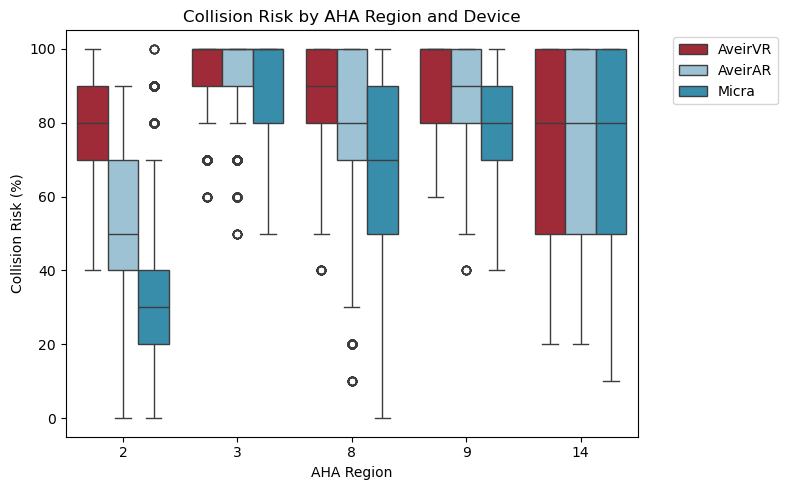

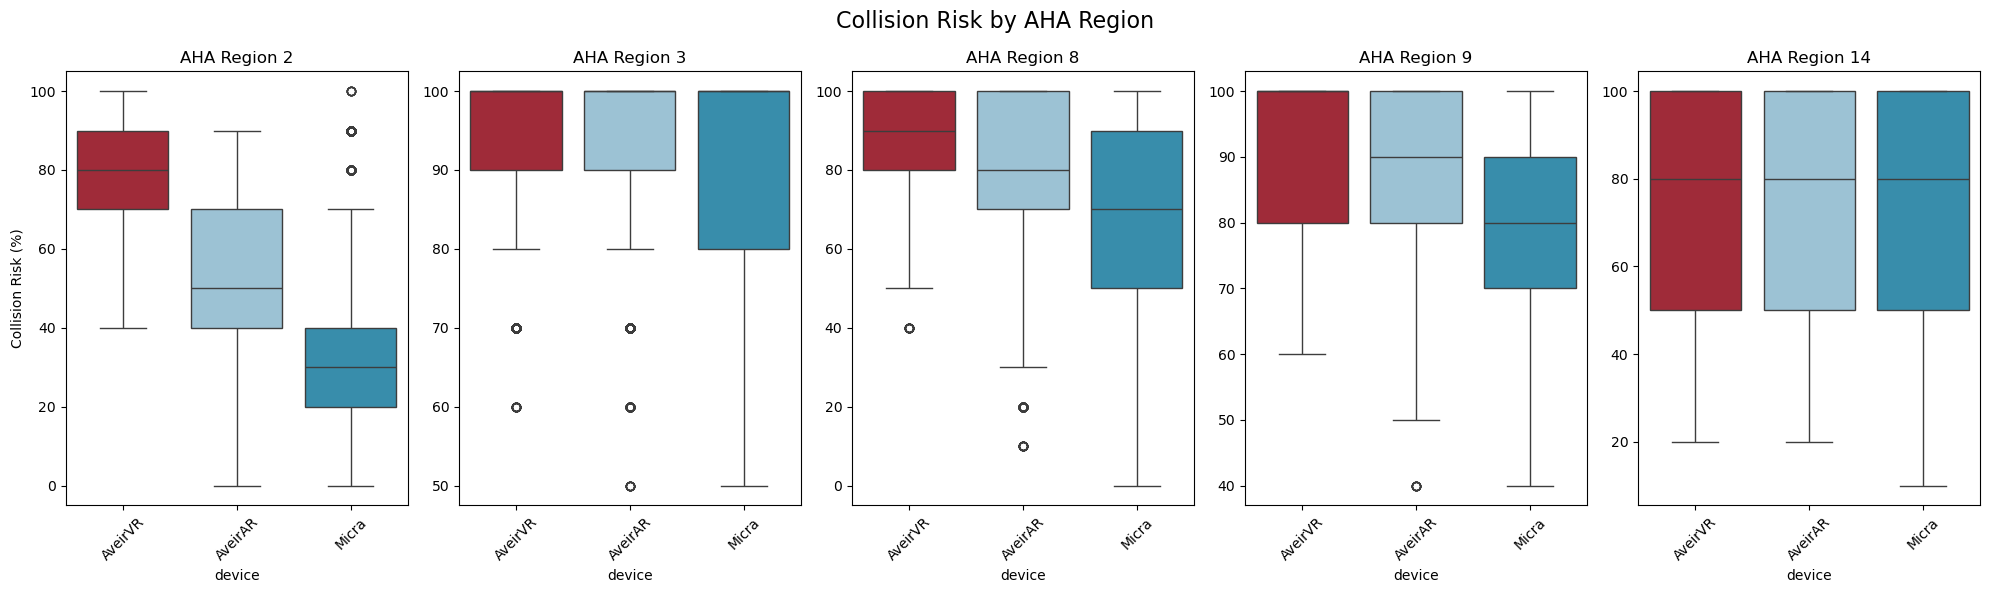


Analysis completed successfully.
DataFrame shape: (98892, 6)
Results: {'overall': {'anova': {'f_stat': np.float64(3897.684462317093), 'p_value': np.float64(0.0)}, 'pairwise': {'AveirVR_vs_AveirAR': {'t_stat': np.float64(47.84534999320689), 'p_value': np.float64(0.0)}, 'AveirVR_vs_Micra': {'t_stat': np.float64(86.59034201576061), 'p_value': np.float64(0.0)}, 'AveirAR_vs_Micra': {'t_stat': np.float64(42.4359566809035), 'p_value': np.float64(0.0)}}, 'mixed_effects': {'summary': '            Mixed Linear Model Regression Results\n==============================================================\nModel:             MixedLM Dependent Variable: collision_value\nNo. Observations:  98892   Method:             REML           \nNo. Groups:        5       Scale:              399.2916       \nMin. group size:   17820   Log-Likelihood:     -436509.0288   \nMax. group size:   26532   Converged:          Yes            \nMean group size:   19778.4                                    \n-------------------

In [1]:
# Statistical analysis of the csv files 
import pandas as pd
import numpy as np
import os
import csv
from scipy import stats
from itertools import combinations
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

def collect_collision_data(collision_field, lengths=[None, 15, 20, 25, 30, 35, 40, 45], verbose=False):
    """
    Collect collision data for all devices and AHA regions into a DataFrame.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter for file naming
    
    Returns:
    --------
    df : pandas.DataFrame
        DataFrame with columns: device, AHA_region, theta, z, collision_value, init_len
    """
    
    # Initialize list to store all data
    all_data = []
    
    # Device specifications
    device_specs = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'Micra': 25.9
    }
    
    for device in ['AveirVR', 'AveirAR', 'Micra']:
        # Get initial length for this device
        init_len = device_specs.get(device)

        if verbose: 
            print(f'Processing device: {device}, initial length: {init_len}')
        
        if init_len is None:
            print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')
            continue
            
        # Set output path
        if collision_field == 'Combined_Collision':
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}/'
        else:
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}/{collision_field}/'
        
        for length_input in lengths:
            if length_input is None: 
                length = init_len
            else:
                length = length_input

            if verbose: 
                print(f'Processing device: {device}, length: {length}')

            # Process each AHA region
            for AHA_region in [2, 3, 8, 9, 14]:
                csv_region_outfile = f'{images_outpath}/csv/{AHA_region}_L{length}.csv'
                if verbose: 
                    print(f'Processing {csv_region_outfile}')
                
                if os.path.exists(csv_region_outfile):
                    try:
                        with open(csv_region_outfile, 'r') as csvfile:
                            reader = csv.reader(csvfile)
                            header = next(reader)
                            data = [row for row in reader]
                        
                        # Convert to numpy array
                        data = np.array(data, dtype=float)
                        
                        if len(data) > 0:
                            # Extract values
                            theta = data[:, 0]
                            z = data[:, 1]
                            collision_values = data[:, 2]
                            
                            # Add to collection
                            for i in range(len(collision_values)):
                                all_data.append({
                                    'device': device,
                                    'AHA_region': AHA_region,
                                    'theta': theta[i],
                                    'z': z[i],
                                    'collision_value': collision_values[i],
                                    'length': length
                                })
                            if verbose: 
                                print(f'  -> Loaded {len(collision_values)} data points')
                        else:
                            print(f'  -> No data found in file')
                            
                    except Exception as e:
                        print(f'  -> Error reading file: {e}')
                else:
                    print(f'  -> File not found')
        
    # Convert to DataFrame
    df = pd.DataFrame(all_data)
    if verbose: 
        print(f'\nTotal data points collected: {len(df)}')
        print(f'Devices: {df["device"].unique()}')
        print(f'AHA regions: {sorted(df["AHA_region"].unique())}')
    
    return df

def analyze_device_differences(df):
    
    """
    Perform statistical  comparing collision values between devices,
    including ANOVA, pairwise t-tests, and a mixed-effects model.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with 'device', 'collision_value', and 'AHA_region' columns.
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}

    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    df['collision_value'] *= 10
    # Summary statistics by device
    summary_stats = df.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(summary_stats)
    
    print("\n" + "="*60)
    summary_stats = df.groupby(['device', 'AHA_region'])['collision_value'].agg([
        'mean', 'std' ]).round(1)

    #print("\nSummary Statistics by Device and AHA region:")
    #print(summary_stats)

    # Overall ANOVA and pairwise t-tests
    devices = df['device'].unique()
    device_groups = [df[df['device'] == device]['collision_value'].values for device in devices]
    
    f_stat, p_anova = stats.f_oneway(*device_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")

    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for device1, device2 in combinations(devices, 2):
        group1 = df[df['device'] == device1]['collision_value'].values
        group2 = df[df['device'] == device2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{device1}_vs_{device2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ device", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)
    
    results['by_region'] = {}
    
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(1)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['device'] == device]['collision_value'].values 
                         for device in devices]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_devices = region_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = region_data[region_data['device'] == device1]['collision_value'].values
                group2 = region_data[region_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")
    
    return results

def analyse_length_difference(df, device='Micra'):
    """
    Perform statistical analysis comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    
    # Overall comparison (all regions combined)
    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    df=df[df['device']==device]
    # Summary statistics by device
    summary_stats = df.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(summary_stats)

    # Overall ANOVA
    lengths = df['length'].unique()
    length_groups = [df[df['length'] == length]['collision_value'].values for length in lengths]
    f_stat, p_anova = stats.f_oneway(*length_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }   

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")       
    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for length1, length2 in combinations(lengths, 2):   
        group1 = df[df['length'] == length1]['collision_value'].values
        group2 = df[df['length'] == length2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{length1}_vs_{length2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}") 
    # Mixed Effects Model
    print(f"\nMixed Effects Model (length = fixed, region = random):")
    try:        
        model = smf.mixedlm("collision_value ~ length", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)   

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)           

    results['by_region'] = {}
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['length'] == length]['collision_value'].values 
                         for length in lengths]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_lengths = region_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = region_data[region_data['length'] == length1]['collision_value'].values
                group2 = region_data[region_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")   

                    
    return results

def analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=list(range(15, 50, 5))):
    """
    Perform statistical analysis comparing collision values between devices and lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    devices : list
        List of devices to compare (default: ['Micra', 'AveirAR', 'AveirVR'])
    lengths : list
        List of lengths to compare (default: [15, 20, 25, 30, 35, 40, 45])
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    df['collision_value'] = df['collision_value']*10
    # Filter data for specified devices and lengths
    df_filtered = df[(df['device'].isin(devices)) & (df['length'].isin(lengths))]
    
    print(f"Analysis for devices: {devices}")
    print(f"Analysis for lengths: {lengths}")
    print(f"Total data points: {len(df_filtered)}")
    
    # Overall comparison (all regions combined)
    print("\n" + "="*80)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*80)
    
    # Summary statistics by device and length
    summary_stats = df_filtered.groupby(['device', 'length'])['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device and Length:")
    print(summary_stats)
    
    # Summary statistics by device only
    device_stats = df_filtered.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(device_stats)
    
    # Summary statistics by length only
    length_stats = df_filtered.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(length_stats)

    # Two-way ANOVA (device × length)
    print(f"\nTwo-way ANOVA (Device × Length):")
    try:
        import statsmodels.api as sm
        from statsmodels.formula.api import ols
        
        # Two-way ANOVA
        model = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                   data=df_filtered).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)
        print(anova_table)
        
        results['overall'] = {
            'two_way_anova': anova_table.to_dict(),
            'device_comparisons': {},
            'length_comparisons': {},
            'device_length_combinations': {},
            'mixed_effects': {}
        }
    except Exception as e:
        print(f"  Error fitting two-way ANOVA: {e}")
        results['overall'] = {'error': str(e)}

    # Device comparisons (across all lengths)
    print(f"\nDevice Comparisons (across all lengths):")
    device_groups = [df_filtered[df_filtered['device'] == device]['collision_value'].values 
                    for device in devices]
    
    # ANOVA for devices
    f_stat_device, p_anova_device = stats.f_oneway(*device_groups)
    print(f"ANOVA F-statistic: {f_stat_device:.4f}")
    print(f"ANOVA p-value: {p_anova_device:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_device < 0.05 else 'No'}")
    
    # Pairwise t-tests between devices
    print(f"\nPairwise t-tests between devices:")
    for device1, device2 in combinations(devices, 2):
        group1 = df_filtered[df_filtered['device'] == device1]['collision_value'].values
        group2 = df_filtered[df_filtered['device'] == device2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['device_comparisons'][f'{device1}_vs_{device2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Length comparisons (across all devices)
    print(f"\nLength Comparisons (across all devices):")
    length_groups = [df_filtered[df_filtered['length'] == length]['collision_value'].values 
                    for length in lengths]
    
    # ANOVA for lengths
    f_stat_length, p_anova_length = stats.f_oneway(*length_groups)
    print(f"ANOVA F-statistic: {f_stat_length:.4f}")
    print(f"ANOVA p-value: {p_anova_length:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_length < 0.05 else 'No'}")
    
    # Pairwise t-tests between lengths
    print(f"\nPairwise t-tests between lengths:")
    for length1, length2 in combinations(lengths, 2):
        group1 = df_filtered[df_filtered['length'] == length1]['collision_value'].values
        group2 = df_filtered[df_filtered['length'] == length2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['length_comparisons'][f'{length1}_vs_{length2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device + length = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ C(device) + C(length)", 
                           df_filtered, groups=df_filtered["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by Device (comparing lengths within each device)
    print("\n" + "="*80)
    print("ANALYSIS BY DEVICE (comparing lengths within each device)")
    print("="*80)
    
    results['by_device'] = {}
    for device in devices:
        print(f"\nDevice: {device}")
        device_data = df_filtered[df_filtered['device'] == device]
        
        if len(device_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this device
        device_length_stats = device_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(device_length_stats)
        
        # ANOVA for lengths within this device
        device_length_groups = [device_data[device_data['length'] == length]['collision_value'].values 
                               for length in lengths]
        non_empty_groups = [g for g in device_length_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_device_length, p_anova_device_length = stats.f_oneway(*non_empty_groups)
        results['by_device'][device] = {
            'anova': {'f_stat': f_stat_device_length, 'p_value': p_anova_device_length},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_device_length:.4f}, p={p_anova_device_length:.6f} {'*' if p_anova_device_length < 0.05 else ''}")
        
        # Pairwise comparisons for lengths within this device
        available_lengths = device_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise length comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = device_data[device_data['length'] == length1]['collision_value'].values
                group2 = device_data[device_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_device'][device]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by Length (comparing devices within each length)
    print("\n" + "="*80)
    print("ANALYSIS BY LENGTH (comparing devices within each length)")
    print("="*80)
    
    results['by_length'] = {}
    for length in lengths:
        print(f"\nLength: {length}")
        length_data = df_filtered[df_filtered['length'] == length]
        
        if len(length_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this length
        length_device_stats = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(length_device_stats)
        
        # ANOVA for devices within this length
        length_device_groups = [length_data[length_data['device'] == device]['collision_value'].values 
                               for device in devices]
        non_empty_groups = [g for g in length_device_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_length_device, p_anova_length_device = stats.f_oneway(*non_empty_groups)
        results['by_length'][length] = {
            'anova': {'f_stat': f_stat_length_device, 'p_value': p_anova_length_device},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_length_device:.4f}, p={p_anova_length_device:.6f} {'*' if p_anova_length_device < 0.05 else ''}")
        
        # Pairwise comparisons for devices within this length
        available_devices = length_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise device comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = length_data[length_data['device'] == device1]['collision_value'].values
                group2 = length_data[length_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_length'][length]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by AHA Region
    print("\n" + "="*80)
    print("ANALYSIS BY AHA REGION")
    print("="*80)
    
    results['by_region'] = {}
    for region in sorted(df_filtered['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df_filtered[df_filtered['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats by device and length within region
        region_stats = region_data.groupby(['device', 'length'])['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Two-way ANOVA within region (if sufficient data)
        try:
            if len(region_data) > 10:  # Minimum threshold for meaningful analysis
                model_region = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                                 data=region_data).fit()
                anova_table_region = sm.stats.anova_lm(model_region, typ=2)
                print(f"  Two-way ANOVA for region {region}:")
                print(anova_table_region)
                
                results['by_region'][region] = {
                    'two_way_anova': anova_table_region.to_dict(),
                    'sample_size': len(region_data)
                }
            else:
                print(f"  Insufficient data for ANOVA (n={len(region_data)})")
                results['by_region'][region] = {'insufficient_data': len(region_data)}
        except Exception as e:
            print(f"  Error in regional analysis: {e}")
            results['by_region'][region] = {'error': str(e)}
    
    return results
def boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=[15, 20, 25, 30, 35, 40, 45]):
    """
    Create boxplots comparing collision values between devices for different lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    length_column : str, default='length'
        Name of the column containing length data
    expected_devices : list, default=['Micra', 'AveirAR', 'AveirVR']
        List of expected device names
    expected_lengths : list, default=[15, 20, 25, 30, 35, 40, 45]
        List of expected length values
    """
    # import matplotlib.pyplot as plt
    # import seaborn as sns
    # import numpy as np
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    
    # Validate data
    #validate_devices(df, expected_devices)
    sns.color_palette("coolwarm", as_cmap=True)

    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }

    # Check if length column exists
    if length_column not in df.columns:
        print(f"Error: Column '{length_column}' not found in DataFrame")
        print(f"Available columns: {list(df.columns)}")
        return
    
    # Get unique lengths and sort them
    unique_lengths = sorted(df[length_column].unique())
    n_lengths = len(unique_lengths)
    
    # Check for missing lengths
    missing_lengths = set(expected_lengths) - set(unique_lengths)
    if missing_lengths:
        print(f"Warning: Missing expected lengths: {sorted(list(missing_lengths))}")
    
    print(f"Analyzing {len(expected_devices)} devices across {n_lengths} lengths")
    print(f"Devices: {expected_devices}")
    print(f"Lengths: {unique_lengths}")
    print("-" * 60)
    
    # Figure 1: Overall comparison across all lengths
    fig, ax = plt.subplots(1, 1, figsize=(12, 6))
    df['collision_value'] = df['collision_value'].astype(float)*10  # Ensure collision_value is float and scaled to percentage
    # Create boxplot with length on x-axis and collision_value on y-axis, grouped by device
    sns.boxplot(data=df, x=length_column, y='collision_value', hue='device', palette=device_colors, ax=ax)
    ax.set_title('Collision Risk by Length and Device', fontsize=14)
    ax.set_ylabel('Collision Risk (%)')
    ax.set_xlabel('Length')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/All_lengths_output.png', dpi=300)
    plt.show()
    
    # Figure 2: Optimized layout for 7 lengths (3 rows x 3 columns, with 2 empty spots)
    if n_lengths > 1:
        # For 7 lengths, use 3x3 grid
        cols = 3
        rows = 3
        
        fig, axes = plt.subplots(rows, cols, figsize=(12, 10))
        fig.suptitle('Collision Values by Device for Different Lengths\n(Micra vs AveirAR vs AveirVR)', fontsize=16)
        
        # Flatten axes for easier indexing
        axes_flat = axes.flatten()
        
        for i, length in enumerate(unique_lengths):
            if i < len(axes_flat):
                length_data = df[df[length_column] == length]
                
                # Create boxplot for this specific length
                sns.boxplot(data=length_data, x='device', y='collision_value', ax=axes_flat[i])
                axes_flat[i].set_title(f'Length: {length}mm', fontweight='bold')
                axes_flat[i].set_ylabel('Collision Risk (%)' if i % cols == 0 else '')
                axes_flat[i].set_xlabel('Device' if i >= (rows-1)*cols else '')
                axes_flat[i].tick_params(axis='x', rotation=45)
                
                # Add sample size annotation
                sample_sizes = length_data.groupby('device').size()
                for j, device in enumerate(length_data['device'].unique()):
                    if device in sample_sizes:
                        axes_flat[i].text(j, axes_flat[i].get_ylim()[1]*0.95, 
                                        f'n={sample_sizes[device]}', 
                                        ha='center', va='top', fontsize=8)
        
        # Hide unused subplots (last 2 spots in 3x3 grid)
        for i in range(n_lengths, len(axes_flat)):
            axes_flat[i].set_visible(False)
        
        plt.tight_layout()
        plt.show()
    
    # Figure 3: Statistical summary
    print("\nStatistical Summary by Length and Device:")
    print("=" * 60)
    
    for length in unique_lengths:
        print(f"\nLength: {length}")
        length_data = df[df[length_column] == length]
        summary = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'min', 'max', 'median'
        ]).round(3)
        print(summary)
    
    # Figure 4: Violin plot alternative (if there are enough data points)
    # if len(df) > 20:  # Only create violin plot if we have sufficient data
    #     fig, ax = plt.subplots(1, 1, figsize=(12, 6))
        
    #     sns.violinplot(data=df, x=length_column, y='collision_value', hue='device', ax=ax)
    #     ax.set_title('Distribution of Collision Values by Length and Device (Violin Plot)', fontsize=14)
    #     ax.set_ylabel('Collision Risk (%)')
    #     ax.set_xlabel('Length')
    #     ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        
    #     plt.tight_layout()
        
    #     plt.show()

def create_visualizations(df):
    """
    Create visualizations comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    """
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    sns.color_palette("coolwarm", as_cmap=True)
    # Create a color mapping for specific devices
    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }
    # Figure 1: Overall comparison
    fig, axes = plt.subplots(1, 1, figsize=(8, 5))
    #fig.suptitle('Device Collision Value Comparison', fontsize=16)
    
    # Box plot by AHA region
    sns.boxplot(data=df, x='AHA_region', y='collision_value', hue='device',palette=device_colors)   
    axes.set_title('Collision Risk by AHA Region and Device')
    axes.set_ylabel('Collision Risk (%)')
    axes.set_xlabel('AHA Region')
    axes.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/Init_length_AHA_regions_output.png', bbox_inches='tight')    

    plt.show()
    
    # Figure 2: Detailed region-by-region comparison
    regions = sorted(df['AHA_region'].unique())
    n_regions = len(regions)
    fig, axes = plt.subplots(1, n_regions, figsize=(4*n_regions, 6))
    if n_regions == 1:
        axes = [axes]
    
    fig.suptitle('Collision Risk by AHA Region', fontsize=16)
    
    for i, region in enumerate(regions):
        region_data = df[df['AHA_region'] == region]
        sns.boxplot(data=region_data, x='device', y='collision_value', ax=axes[i], hue='device',palette=device_colors)   
        axes[i].set_title(f'AHA Region {region}')
        axes[i].set_ylabel('Collision Risk (%)' if i == 0 else '')
        axes[i].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    # Save image to file 
    plt.show()
# Main execution
def process_df(collision_field, length):
    """
    Main function to run the complete analysis.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter
    """
    
    print(f"Starting device collision analysis for {collision_field}...")
    
    # Collect data
    df = collect_collision_data(collision_field, length)
    
    if len(df) == 0:
        print("No data collected. Please check file paths and data availability.")
        return None, None
    
    # Perform statistical analysis
    if length[0] is None: 
        results = analyze_device_differences(df)
        create_visualizations(df)    
    else: 
        #results = analyse_length_difference(df, device='Micra')

        results=analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=length)
        boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=length)
    return df, results
if __name__ == "__main__":
    # Example usage
    for collision_field in ['Combined_Collision']: #, 'RV_Collision', 'TV_Collision', 'PM_Collision']:   # Change as needed
        #length = None  # None - uses initial length based on device
        # Only test for initial lengths
        df, results = process_df(collision_field, length=[None])

        # All lengths comparison
        #df, results = process_df(collision_field, length=[15, 20, 25, 30, 35, 40, 45])  # Example lengths
                        
        if df is not None and results is not None:
            print("\nAnalysis completed successfully.")
            print("DataFrame shape:", df.shape)
            print("Results:", results)
        else:
            print("Analysis failed.")
# Example usage:
# df, results = main('Combined_Collision', 30)
# or
# df, results = main('your_collision_field', your_length)

DIAMETER-COLLISION CORRELATION ANALYSIS


,device,AHA_region,theta,z,collision_value,length,region
0,AveirVR,2,210.000000,0.000000,5.0,15,2
1,AveirVR,2,210.670391,0.000000,5.0,15,2
2,AveirVR,2,211.340782,0.000000,5.0,15,2
3,AveirVR,2,212.011173,0.000000,5.0,15,2
4,AveirVR,2,212.681564,0.000000,5.0,15,2
...,...,...,...,...,...,...,...
692239,Micra,14,296.480447,0.326633,0.0,45,14
692240,Micra,14,297.150838,0.326633,0.0,45,14
692241,Micra,14,297.821229,0.326633,0.0,45,14
692242,Micra,14,298.491620,0.326633,0.0,45,14


Overall Correlation: r = 0.0051, p = 2.09e-05
AveirVR: r = 0.0025, p = 2.21e-01
AveirAR: r = 0.0023, p = 2.69e-01
Micra: r = 0.0032, p = 1.21e-01

LINEAR REGRESSION ANALYSIS
Simple Regression (Collision ~ Diameter):
  R² = 0.0000
  Coefficient = 0.0116
  Intercept = 1.7674

Multiple Regression (Collision ~ Diameter + Device):
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                1.8005      0.021     84.196      0.000       1.759       1.842
C(device)[T.AveirVR]     0.0320      0.010      3.347      0.001       0.013       0.051
C(device)[T.Micra]      -0.0214      0.009     -2.255      0.024      -0.040      -0.003
diameter                 0.0064      0.003      2.220      0.026       0.001       0.012

Interaction Model (Collision ~ Diameter × Device):
                                    coef    std err          t      P>|t|      [0.025 

/tmp/ipykernel_68780/45020249.py:229: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('diameter_collision_analysis.png', dpi=300, bbox_inches='tight')


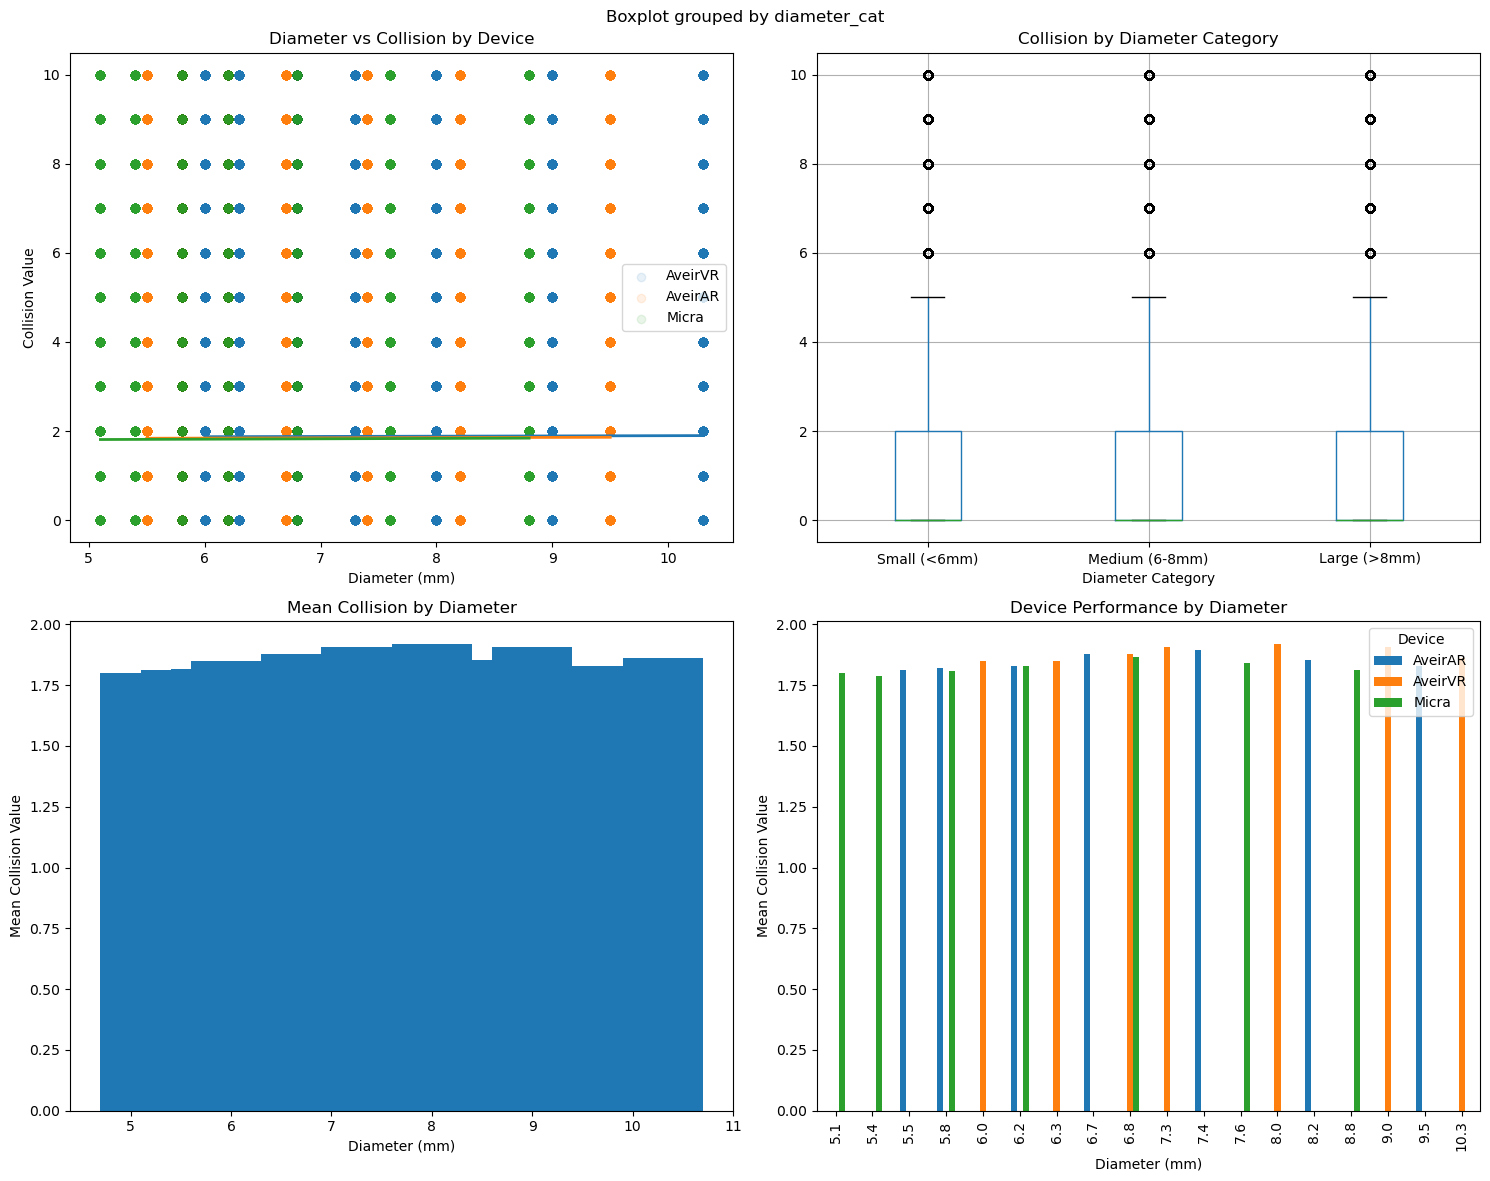

Analysis complete! Plots saved as 'diameter_collision_analysis.png'

SUMMARY STATISTICS TABLE
                  Count  Mean_Collision  Std_Collision  Length_mm
device  diameter                                                 
AveirAR 5.5       32964           1.814          3.125         45
        5.8       32964           1.820          3.133         40
        6.2       32964           1.831          3.160         35
        6.7       32964           1.878          3.224         30
        7.4       32964           1.895          3.246         25
        8.2       32964           1.854          3.217         20
        9.5       32964           1.829          3.170         15
AveirVR 6.0       32964           1.851          3.147         45
        6.3       32964           1.850          3.165         40
        6.8       32964           1.878          3.224         35
        7.3       32964           1.908          3.251         30
        8.0       32964           1.918         

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm
from statsmodels.formula.api import ols, mixedlm
from statsmodels.stats.anova import anova_lm

def device_specs(): 
    # Device specifications
    device_specs = {
        'Micra': {
            'volume': 0.913,
            'original_length': 25.90,
            'original_diameter': 6.70,
            'diameters': {15: 8.8, 20: 7.6, 25: 6.8, 30: 6.2, 35: 5.8, 40: 5.4, 45: 5.1}
        },
        'AveirAR': {
            'volume': 1.068,
            'original_length': 32.20,
            'original_diameter': 6.50,
            'diameters': {15: 9.5, 20: 8.2, 25: 7.4, 30: 6.7, 35: 6.2, 40: 5.8, 45: 5.5}
        },
        'AveirVR': {
            'volume': 1.261,
            'original_length': 38.00,
            'original_diameter': 6.50,
            'diameters': {15: 10.3, 20: 9.0, 25: 8.0, 30: 7.3, 35: 6.8, 40: 6.3, 45: 6.0}
        }
    }
    return device_specs

# Assume your collision data is in a DataFrame called 'df'
# with columns: 'device', 'length', 'collision_value', 'region'
# df = pd.read_csv('your_collision_data.csv')

def add_diameter_column(df, device_specs):
    """Add diameter column based on device and length"""
    df['diameter'] = df.apply(
        lambda row: device_specs[row['device']]['diameters'][row['length']], 
        axis=1
    )
    return df



# 1. CORRELATION ANALYSIS
print("="*60)
print("DIAMETER-COLLISION CORRELATION ANALYSIS")
print("="*60)

def diameters_stats(df): 

    # Add diameter to your dataframe
    df = add_diameter_column(df, device_specs())

    # Overall correlation
    overall_corr = stats.pearsonr(df['diameter'], df['collision_value'])
    print(f"Overall Correlation: r = {overall_corr[0]:.4f}, p = {overall_corr[1]:.2e}")

    # Device-specific correlations
    device_correlations = {}
    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        corr = stats.pearsonr(device_data['diameter'], device_data['collision_value'])
        device_correlations[device] = corr
        print(f"{device}: r = {corr[0]:.4f}, p = {corr[1]:.2e}")

    # 2. LINEAR REGRESSION MODELS
    print("\n" + "="*60)
    print("LINEAR REGRESSION ANALYSIS")
    print("="*60)

    # Simple regression: Collision ~ Diameter
    X_simple = df[['diameter']]
    y = df['collision_value']
    model_simple = LinearRegression().fit(X_simple, y)
    r2_simple = r2_score(y, model_simple.predict(X_simple))

    print(f"Simple Regression (Collision ~ Diameter):")
    print(f"  R² = {r2_simple:.4f}")
    print(f"  Coefficient = {model_simple.coef_[0]:.4f}")
    print(f"  Intercept = {model_simple.intercept_:.4f}")

    # Multiple regression with statsmodels for p-values
    model_multi = ols('collision_value ~ diameter + C(device)', data=df).fit()
    print(f"\nMultiple Regression (Collision ~ Diameter + Device):")
    print(model_multi.summary().tables[1])

    # Interaction model
    model_interaction = ols('collision_value ~ diameter * C(device)', data=df).fit()
    print(f"\nInteraction Model (Collision ~ Diameter × Device):")
    print(model_interaction.summary().tables[1])

    # 3. ANOVA BY DIAMETER CATEGORIES
    print("\n" + "="*60)
    print("DIAMETER CATEGORY ANALYSIS")
    print("="*60)

    # Create diameter categories
    df['diameter_cat'] = pd.cut(df['diameter'], 
                            bins=[0, 6, 8, 12], 
                            labels=['Small (<6mm)', 'Medium (6-8mm)', 'Large (>8mm)'])

    # ANOVA across diameter categories
    diameter_anova = ols('collision_value ~ C(diameter_cat)', data=df).fit()
    anova_results = anova_lm(diameter_anova, typ=2)
    print("ANOVA - Diameter Categories:")
    print(anova_results)

    # Pairwise comparisons within diameter categories
    from scipy.stats import ttest_ind
    categories = df['diameter_cat'].unique()
    categories = categories[~pd.isna(categories)]  # Remove NaN

    print("\nPairwise t-tests between diameter categories:")
    for i, cat1 in enumerate(categories):
        for cat2 in categories[i+1:]:
            group1 = df[df['diameter_cat'] == cat1]['collision_value']
            group2 = df[df['diameter_cat'] == cat2]['collision_value']
            t_stat, p_val = ttest_ind(group1, group2)
            print(f"  {cat1} vs {cat2}: t = {t_stat:.4f}, p = {p_val:.6f}")

    # 4. MIXED EFFECTS MODEL (if region data available)
    print("\n" + "="*60)
    print("MIXED EFFECTS MODEL")
    print("="*60)

    try:
        # Mixed effects with region as random effect
        mixed_model = mixedlm("collision_value ~ diameter + C(device)", 
                            df, groups=df["region"]).fit()
        print("Mixed Effects Model (Random: Region):")
        print(mixed_model.summary())
    except:
        print("Mixed effects model requires 'region' column in data")

    # 5. DEVICE-SPECIFIC DIAMETER ANALYSIS
    print("\n" + "="*60)
    print("DEVICE-SPECIFIC DIAMETER ANALYSIS")
    print("="*60)

    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        
        print(f"\n{device} - Diameter vs Collision:")
        
        # Regression for this device
        X_dev = device_data[['diameter']]
        y_dev = device_data['collision_value']
        model_dev = LinearRegression().fit(X_dev, y_dev)
        r2_dev = r2_score(y_dev, model_dev.predict(X_dev))
        
        print(f"  R² = {r2_dev:.4f}")
        print(f"  Slope = {model_dev.coef_[0]:.4f}")
        print(f"  Mean collision by diameter:")
        
        diameter_means = device_data.groupby('diameter')['collision_value'].agg(['mean', 'std', 'count'])
        for diameter, row in diameter_means.iterrows():
            print(f"    {diameter}mm: {row['mean']:.3f} ± {row['std']:.3f} (n={row['count']})")

    # 6. OPTIMAL DIAMETER ANALYSIS
    print("\n" + "="*60)
    print("OPTIMAL DIAMETER IDENTIFICATION")
    print("="*60)

    # Find diameter with minimum collision rate
    diameter_summary = df.groupby('diameter')['collision_value'].agg(['mean', 'std', 'count'])
    optimal_diameter = diameter_summary['mean'].idxmin()
    min_collision = diameter_summary.loc[optimal_diameter, 'mean']

    print(f"Optimal diameter: {optimal_diameter}mm")
    print(f"Minimum collision rate: {min_collision:.3f}")

    print("\nDiameter performance ranking:")
    diameter_ranking = diameter_summary.sort_values('mean')
    for i, (diameter, row) in enumerate(diameter_ranking.iterrows(), 1):
        print(f"  {i}. {diameter}mm: {row['mean']:.3f} ± {row['std']:.3f}")

    # 7. VISUALIZATION CODE
    print("\n" + "="*60)
    print("CREATING VISUALIZATIONS")
    print("="*60)

    # Create comprehensive plots
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # Plot 1: Scatter plot by device
    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        axes[0,0].scatter(device_data['diameter'], device_data['collision_value'], 
                        alpha=0.1, label=device)
        
        # Add regression line
        z = np.polyfit(device_data['diameter'], device_data['collision_value'], 1)
        p = np.poly1d(z)
        x_range = np.linspace(device_data['diameter'].min(), device_data['diameter'].max(), 100)
        axes[0,0].plot(x_range, p(x_range), linewidth=2)

    axes[0,0].set_xlabel('Diameter (mm)')
    axes[0,0].set_ylabel('Collision Value')
    axes[0,0].set_title('Diameter vs Collision by Device')
    axes[0,0].legend()

    # Plot 2: Box plot by diameter category
    df.boxplot(column='collision_value', by='diameter_cat', ax=axes[0,1])
    axes[0,1].set_title('Collision by Diameter Category')
    axes[0,1].set_xlabel('Diameter Category')

    # Plot 3: Mean collision by diameter
    diameter_means_all = df.groupby('diameter')['collision_value'].mean()
    axes[1,0].bar(diameter_means_all.index, diameter_means_all.values)
    axes[1,0].set_xlabel('Diameter (mm)')
    axes[1,0].set_ylabel('Mean Collision Value')
    axes[1,0].set_title('Mean Collision by Diameter')

    # Plot 4: Device comparison at each diameter
    diameter_device = df.groupby(['diameter', 'device'])['collision_value'].mean().unstack()
    diameter_device.plot(kind='bar', ax=axes[1,1])
    axes[1,1].set_xlabel('Diameter (mm)')
    axes[1,1].set_ylabel('Mean Collision Value')
    axes[1,1].set_title('Device Performance by Diameter')
    axes[1,1].legend(title='Device')

    plt.tight_layout()
    plt.savefig('diameter_collision_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("Analysis complete! Plots saved as 'diameter_collision_analysis.png'")

    # 8. SUMMARY STATISTICS TABLE
    print("\n" + "="*60)
    print("SUMMARY STATISTICS TABLE")
    print("="*60)

    summary_table = df.groupby(['device', 'diameter']).agg({
        'collision_value': ['count', 'mean', 'std'],
        'length': 'first'  # Just to show corresponding length
    }).round(3)

    summary_table.columns = ['Count', 'Mean_Collision', 'Std_Collision', 'Length_mm']
    print(summary_table)
    
def main():
    collision_field = 'TV_Collision'
    length=[15, 20, 25, 30, 35, 40, 45]

    # Collect data
    df = collect_collision_data(collision_field, length)
    df['region']=df['AHA_region']
    display(df)
    diameters_stats(df)
    # Perform statistical analysis
if __name__ == "__main__":
    main()